# Rafael Russo
### Solução de exercício proposto

Premissas completas no `README.md`.

## Parte 1 – Preparação da base

In [1]:
import pandas as pd

pd.set_option("display.width", 200, "display.max_columns", 30)

### Carga e limpeza

In [2]:
# cabeçalho está na linha 3 (linhas 1-2 são aviso/lixo)
cot = pd.read_excel("COTAÇÕES - CASE (2).xlsx", header=2, dtype=str)

# datas viram datetime; "Última Ação em" tem texto "Vazio" -> vira nulo (não é usada em cálculos)
cot["Dt. Criação Sol."] = pd.to_datetime(cot["Dt. Criação Sol."], dayfirst=True)
cot["Última Ação em"] = pd.to_datetime(cot["Última Ação em"], errors="coerce")
for c in ["Preço Atual", "Preço Proposto", "Var. Preço Proposto"]:
    cot[c] = cot[c].astype(float)

print(cot.shape, "| duplicadas exatas:", cot.duplicated().sum())
print(cot.isna().sum()[lambda s: s > 0])

(4354, 19) | duplicadas exatas: 0
TipoCotação             88
Última Ação em         122
Preço Atual            206
Preço Proposto         206
Var. Preço Proposto    206
dtype: int64


In [3]:
# nulos de preço (206) e de TipoCotação (88) -> mantidos, não entram nas contas onde não se aplicam
print(cot.loc[cot["Var. Preço Proposto"].isna(), "TipoCotação"].value_counts(dropna=False))

TipoCotação
Prazo             149
FreteComercial     57
Name: count, dtype: int64


In [4]:
sf = pd.read_excel("SalesForce - CASE (2).xlsx", dtype=str)

# lê 1M de linhas (restos de formatação, só Frete/Chapa=0); dados reais: 23.227. Filtro por ID SAP, que também descarta 2 linhas reais sem ID (não cruzam pela chave)
sf = sf[sf["ID da Cotação do SAP"].notna()].copy()
sf[["Frete Comercial", "Chapa"]] = sf[["Frete Comercial", "Chapa"]].astype(float)

sf_todo = sf.copy()  # guardo para mostrar duplicidades também fora do escopo

# registros do SF que não existem em COTAÇÕES (fora do escopo) -> saem
sf = sf[sf["ID da Cotação do SAP"].isin(cot["ID da Cotação do SAP"])]
print(sf.shape)

(4279, 9)


### 4.1 e 4.2 – Frete Comercial e Chapa

In [5]:
chave_sf = ["ID da Cotação do SAP", "Material: Código do material", "Cód. Expedição"]
chave_cot = ["ID da Cotação do SAP", "Material", "Cód. Expedição"]

# 3.1 situação 1: chaves duplicadas no SF (escopo = só cotações presentes em COTAÇÕES)
for nome, df in [("SF todo", sf_todo), ("SF no escopo", sf)]:
    g = df.groupby(chave_sf)["Frete Comercial"].agg(["size", "nunique"])
    print(f"{nome}: {(g['size'] > 1).sum()} chaves duplicadas, {(g['nunique'] > 1).sum()} com frete divergente")

# detalhe das duplicadas no escopo (frete idêntico entre as linhas)
sf[sf.duplicated(chave_sf, keep=False)].sort_values(chave_sf)[chave_sf + ["Frete Comercial", "Chapa"]]

SF todo: 51 chaves duplicadas, 8 com frete divergente
SF no escopo: 4 chaves duplicadas, 0 com frete divergente


,ID da Cotação do SAP,Material: Código do material,Cód. Expedição,Frete Comercial,Chapa
21668,0020323685,1363,B124,0.0,0.0
21953,0020323685,1363,B124,0.0,0.0
21966,0020323710,1063,B108,0.0,0.0
22922,0020323710,1063,B108,0.0,0.0
21849,0020323891,1296,B117,0.0,0.0
22118,0020323891,1296,B117,0.0,0.0
21140,0020324137,1296,B117,0.0,0.0
23032,0020324137,1296,B117,0.0,0.0


In [6]:
# 4 chaves duplicadas no escopo (8 linhas), frete idêntico; regra preventiva: fica a de maior |Frete| (0 tende a ser placeholder), Chapa da mesma linha
sf["abs_frete"] = sf["Frete Comercial"].abs()
sf_unico = (sf.sort_values("abs_frete", ascending=False)
              .drop_duplicates(chave_sf)[chave_sf + ["Frete Comercial", "Chapa"]]
              .rename(columns={"Material: Código do material": "Material"}))

# left join: cotações sem match ficam com Frete/Chapa nulos (nulo != 0)
base = cot.merge(sf_unico, on=chave_cot, how="left")
base["Match SalesForce"] = base["Frete Comercial"].notna().map({True: "Sim", False: "Não"})

assert len(base) == len(cot)  # dedup garante que o join não cria linhas
print(base["Match SalesForce"].value_counts())

Match SalesForce
Sim    4264
Não      90
Name: count, dtype: int64


In [7]:
# 3.1 situação 2: cotações sem correspondência no SF (mantidas, frete nulo)
sem_match = base[base["Match SalesForce"] == "Não"]
print(len(sem_match), "cotações sem match | Frete nulo:", sem_match["Frete Comercial"].isna().all())
print(sem_match["Incoterm"].value_counts())
sem_match[["ID da Cotação do SAP", "Material", "Cód. Expedição", "TipoCotação", "Status da Cotação", "Incoterm"]].head(10)

90 cotações sem match | Frete nulo: True
Incoterm
Sem informação do Sales Force    89
CIF                               1
Name: count, dtype: int64


,ID da Cotação do SAP,Material,Cód. Expedição,TipoCotação,Status da Cotação,Incoterm
126,0020321483,1063,B108,NaN,Rejeitada,Sem informação do Sales Force
200,0020321557,1063,B108,NaN,Aprovada,Sem informação do Sales Force
203,0020321560,1069,B107,NaN,Rejeitada,Sem informação do Sales Force
278,0020321634,1063,B108,NaN,Rejeitada,Sem informação do Sales Force
303,0020321658,1071,B108,NaN,Aprovada,Sem informação do Sales Force
311,0020321666,1341,B115,NaN,Aprovada,Sem informação do Sales Force
383,0020321738,1296,B117,NaN,Aprovada,Sem informação do Sales Force
473,0020321835,1063,B108,NaN,Rejeitada,Sem informação do Sales Force
476,0020321838,1063,B108,NaN,Rejeitada,Sem informação do Sales Force
478,0020321840,1063,B108,NaN,Rejeitada,Sem informação do Sales Force


### 4.3 – Recorrência de aprovações (30 dias)

In [8]:
chave_grupo = ["Código do Cliente", "Material", "Cód. Expedição"]

# elegíveis: Aprovada + Banda/PrecoFixo (nulos de Var. Preço entram como 0 na soma)
elegiveis = base[(base["Status da Cotação"] == "Aprovada") & base["TipoCotação"].isin(["Banda", "PrecoFixo"])]
grupos = {k: g for k, g in elegiveis.groupby(chave_grupo)}

def janela_30d(linha):
    g = grupos.get(tuple(linha[chave_grupo]))
    if g is None:
        return pd.Series([0, 0.0])
    # 30 dias corridos ANTES da data da linha (estrito: exclui a própria linha e o mesmo dia)
    m = (g["Dt. Criação Sol."] < linha["Dt. Criação Sol."]) & (g["Dt. Criação Sol."] >= linha["Dt. Criação Sol."] - pd.Timedelta(days=30))
    return pd.Series([m.sum(), g.loc[m, "Var. Preço Proposto"].sum()])

base[["Qtd. cotações aprovadas 30d", "Soma da variação de desconto 30d"]] = base.apply(janela_30d, axis=1)
print(base[["Qtd. cotações aprovadas 30d", "Soma da variação de desconto 30d"]].describe())

       Qtd. cotações aprovadas 30d  Soma da variação de desconto 30d
count                  4354.000000                       4354.000000
mean                      0.127239                         -1.159724
std                       0.483476                         15.752387
min                       0.000000                       -420.070000
25%                       0.000000                          0.000000
50%                       0.000000                          0.000000
75%                       0.000000                          0.000000
max                       6.000000                        119.660000


In [9]:
# conferência independente em todas as linhas: join entre cotações do mesmo grupo + filtro de datas
par = base[chave_grupo + ["Dt. Criação Sol."]].reset_index().merge(
    elegiveis[chave_grupo + ["Dt. Criação Sol.", "Var. Preço Proposto"]], on=chave_grupo, suffixes=("", "_e"))
d, de = par["Dt. Criação Sol."], par["Dt. Criação Sol._e"]
par = par[(de < d) & (de >= d - pd.Timedelta(days=30))]
chk = par.groupby("index").agg(q=("Var. Preço Proposto", "size"), v=("Var. Preço Proposto", "sum")).reindex(base.index, fill_value=0)

ok_q = (chk["q"] == base["Qtd. cotações aprovadas 30d"]).all()
ok_v = ((chk["v"] - base["Soma da variação de desconto 30d"]).abs() < 1e-9).all()
print("linhas conferidas:", len(base), "| qtd igual:", ok_q, "| soma igual:", ok_v)
print("linhas com recorrência:", (base["Qtd. cotações aprovadas 30d"] > 0).sum())
assert ok_q and ok_v

linhas conferidas: 4354 | qtd igual: True | soma igual: True
linhas com recorrência: 414


### 4.4 – Exportação

In [10]:
base.to_excel("base_consolidada.xlsx", index=False)
print(base.shape)

(4354, 24)


## Parte 2 – Análises de negócio

In [11]:
# helper: top 10 geral e dentro de cada grupo
def top10(df, col, por=None):
    df = df.sort_values(col, ascending=False)
    if por is None:
        return df.head(10).reset_index(drop=True)
    return df.groupby(por).head(10).sort_values([por, col], ascending=[True, False]).reset_index(drop=True)

resultados = {}  # tabelas -> analises.xlsx

In [12]:
import matplotlib.pyplot as plt

AZUL, CINZA = "#2a6fb0", "#c3cad3"

# barras horizontais, uma cor, destaque nas n primeiras, valor escrito na barra
def barh(rotulos, valores, titulo, destaque=1, fmt="{:,.0f}", extra=None):
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(rotulos) + 1.2))
    rotulos, valores = list(rotulos), list(valores)  # posição, não índice do pandas
    extra = None if extra is None else list(extra)
    cores = [AZUL if i < destaque else CINZA for i in range(len(rotulos))]
    ax.barh(range(len(rotulos)), valores, color=cores)
    ax.set_yticks(range(len(rotulos)), rotulos)
    ax.invert_yaxis()
    for i, v in enumerate(valores):
        ax.text(v, i, " " + fmt.format(v) + (f"  ({extra[i]})" if extra is not None else ""), va="center", fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=11, fontweight="bold")
    ax.xaxis.set_visible(False)
    for lado in ["top", "right", "bottom"]:
        ax.spines[lado].set_visible(False)
    ax.set_xlim(0, max(valores) * 1.25)
    plt.tight_layout()
    plt.show()

### 5.1 – Maiores concessões de desconto
Concessão = soma dos valores **negativos** de `Var. Preço Proposto`, em módulo (positivo = aumento de preço, não é desconto; nulo = 0).
Universo: todas as solicitações do período, conforme definição do case. Quantidade = nº de solicitações do cliente.

In [13]:
base["Desconto"] = (-base["Var. Preço Proposto"]).clip(lower=0).fillna(0)

def concessao(por):
    cols = ["Código do Cliente"] if por is None else [por, "Código do Cliente"]
    return (base.groupby(cols).agg(Desconto_acumulado=("Desconto", "sum"), Qtd_solicitacoes=("ID da Cotação do SAP", "size"))
                .reset_index())

resultados["5.1 Total"] = top10(concessao(None), "Desconto_acumulado")
resultados["5.1 Região"] = top10(concessao("Região"), "Desconto_acumulado", "Região")
resultados["5.1 Gestão"] = top10(concessao("Gestão de Vendas"), "Desconto_acumulado", "Gestão de Vendas")
resultados["5.1 Total"]

,Código do Cliente,Desconto_acumulado,Qtd_solicitacoes
0,101080193,1537.32,9
1,101026904,1398.08,19
2,101081286,544.86,2
3,101083476,541.65,3
4,101077085,479.78,1
5,101083625,466.85,1
6,101083055,435.32,1
7,101080539,429.08,2
8,101047814,355.11,1
9,101083325,338.72,2


In [14]:
resultados["5.1 Região"]

,Região,Código do Cliente,Desconto_acumulado,Qtd_solicitacoes
0,Centro-Oeste,101080193,1537.32,9
1,Centro-Oeste,101026904,1398.08,19
2,Centro-Oeste,101083055,435.32,1
3,Centro-Oeste,101032363,258.03,2
4,Centro-Oeste,101076713,189.54,2
5,Centro-Oeste,101033874,189.45,1
6,Centro-Oeste,101083515,180.18,2
7,Centro-Oeste,101037900,139.94,1
8,Centro-Oeste,101055371,123.23,1
9,Centro-Oeste,101048662,118.82,1


In [15]:
resultados["5.1 Gestão"]

,Gestão de Vendas,Código do Cliente,Desconto_acumulado,Qtd_solicitacoes
0,Avenida Paulista,101081286,544.86,2
1,Avenida Paulista,101083476,541.65,3
2,Avenida Paulista,101077085,479.78,1
3,Avenida Paulista,101083625,466.85,1
4,Avenida Paulista,101083055,435.32,1
5,Avenida Paulista,101080539,429.08,2
6,Avenida Paulista,101083294,249.04,3
7,Avenida Paulista,101077697,218.44,3
8,Avenida Paulista,101083515,180.18,2
9,Avenida Paulista,101083202,179.11,1


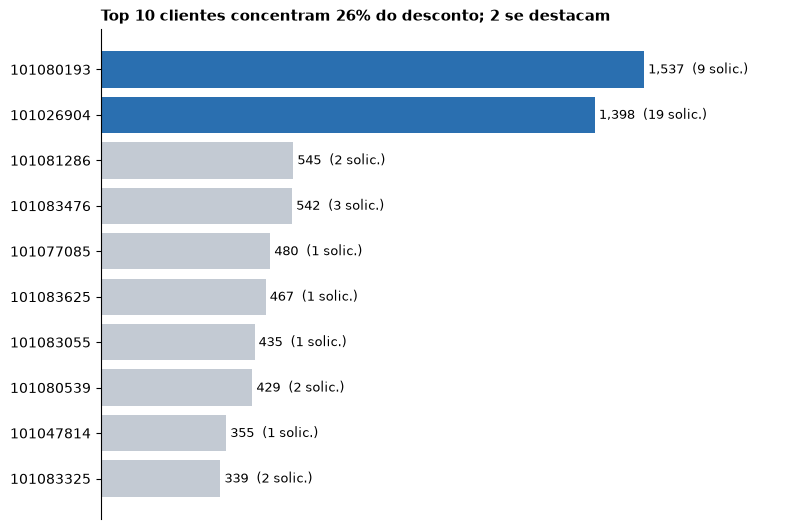

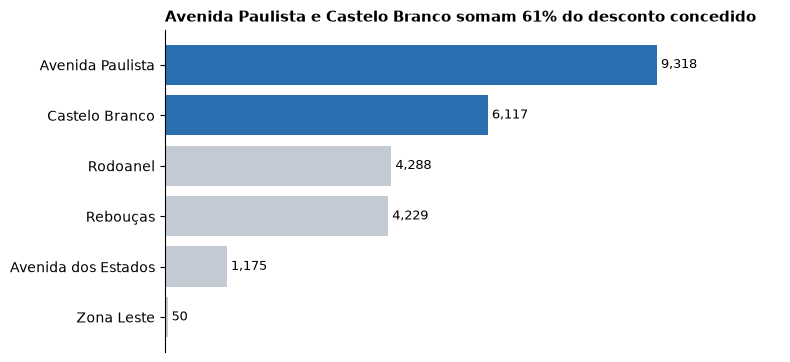

In [16]:
# insight: concentração do desconto nos 10 maiores clientes e por gestão
t = resultados["5.1 Total"]
pct10 = t["Desconto_acumulado"].sum() / base["Desconto"].sum() * 100
barh(t["Código do Cliente"], t["Desconto_acumulado"],
     f"Top 10 clientes concentram {pct10:.0f}% do desconto; 2 se destacam",
     destaque=2, fmt="{:,.0f}", extra=t["Qtd_solicitacoes"].astype(str) + " solic.")

g = base.groupby("Gestão de Vendas")["Desconto"].sum().sort_values(ascending=False)
barh(g.index, g.values, f"{g.index[0]} e {g.index[1]} somam {g.iloc[:2].sum() / g.sum() * 100:.0f}% do desconto concedido", destaque=2)

### 5.2 – Recorrência de aprovações (30d)
A métrica 4.3.1 é por linha, então por cliente uso o **máximo** (pico de recorrência; somar contaria a mesma cotação várias vezes). A soma fica ao lado só como referência.

In [17]:
def recorrencia(por):
    cols = ["Código do Cliente"] if por is None else [por, "Código do Cliente"]
    return (base.groupby(cols)["Qtd. cotações aprovadas 30d"].agg(Max_30d="max", Soma_30d="sum").reset_index())

resultados["5.2 Total"] = top10(recorrencia(None), "Max_30d")
resultados["5.2 Região"] = top10(recorrencia("Região"), "Max_30d", "Região")
resultados["5.2 Gestão"] = top10(recorrencia("Gestão de Vendas"), "Max_30d", "Gestão de Vendas")
resultados["5.2 Total"]

,Código do Cliente,Max_30d,Soma_30d
0,101021141,6.0,15.0
1,101081797,6.0,30.0
2,101078283,6.0,21.0
3,101071737,5.0,15.0
4,101079985,5.0,5.0
5,101030909,4.0,12.0
6,101047355,4.0,10.0
7,101083159,3.0,6.0
8,101074871,3.0,5.0
9,101080193,3.0,15.0


In [18]:
resultados["5.2 Região"]

,Região,Código do Cliente,Max_30d,Soma_30d
0,Centro-Oeste,101078283,6.0,21.0
1,Centro-Oeste,101083159,3.0,6.0
2,Centro-Oeste,101044036,3.0,9.0
3,Centro-Oeste,101080193,3.0,15.0
4,Centro-Oeste,101059806,3.0,3.0
5,Centro-Oeste,101070522,3.0,3.0
6,Centro-Oeste,101034613,2.0,3.0
7,Centro-Oeste,101082417,2.0,3.0
8,Centro-Oeste,101010927,1.0,1.0
9,Centro-Oeste,101013004,1.0,1.0


In [19]:
resultados["5.2 Gestão"]

,Gestão de Vendas,Código do Cliente,Max_30d,Soma_30d
0,Avenida Paulista,101076302,2.0,2.0
1,Avenida Paulista,101065754,1.0,1.0
2,Avenida Paulista,101062661,1.0,1.0
3,Avenida Paulista,101063942,1.0,1.0
4,Avenida Paulista,101077919,1.0,2.0
5,Avenida Paulista,101075099,1.0,1.0
6,Avenida Paulista,101082453,1.0,1.0
7,Avenida Paulista,101009611,1.0,1.0
8,Avenida Paulista,101024130,1.0,1.0
9,Avenida Paulista,101042200,1.0,1.0


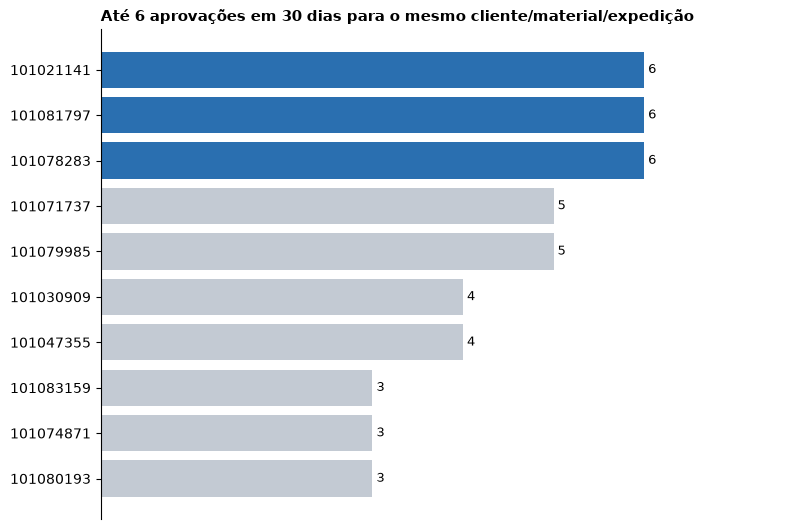

Gestão predominante entre os 5 maiores: Avenida dos Estados


In [20]:
t = resultados["5.2 Total"]
gestao_top = base.loc[base["Código do Cliente"].isin(t["Código do Cliente"].head(5)), "Gestão de Vendas"].mode()[0]
barh(t["Código do Cliente"], t["Max_30d"],
     f"Até {int(t['Max_30d'].iloc[0])} aprovações em 30 dias para o mesmo cliente/material/expedição",
     destaque=3, fmt="{:.0f}")
print("Gestão predominante entre os 5 maiores:", gestao_top)

### 5.3 – Perfil de cliente (cotações aprovadas)

In [21]:
aprovadas = base[base["Status da Cotação"] == "Aprovada"]
perfil = aprovadas["Cliente Condição"].value_counts().rename("Qtd").to_frame()
perfil["% do total"] = (perfil["Qtd"] / perfil["Qtd"].sum() * 100).round(1)
resultados["5.3 Perfil"] = perfil.reset_index()
resultados["5.3 Perfil"]

,Cliente Condição,Qtd,% do total
0,Cresce,1168,36.2
1,Churn,1070,33.2
2,Novo,613,19.0
3,Cai,372,11.5
4,Igual,1,0.0


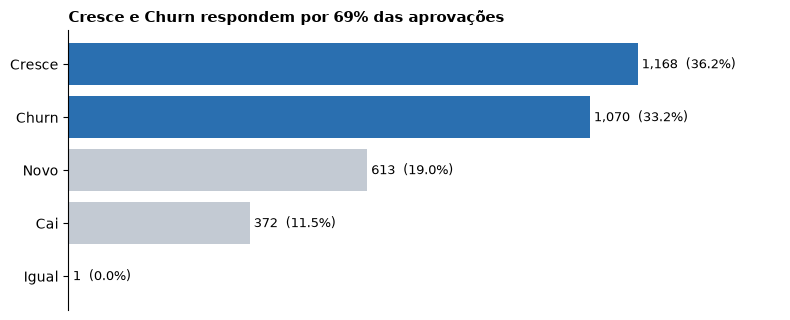

In [22]:
p = resultados["5.3 Perfil"]
barh(p["Cliente Condição"], p["Qtd"],
     f"{p['Cliente Condição'].iloc[0]} e {p['Cliente Condição'].iloc[1]} respondem por {p['% do total'].iloc[:2].sum():.0f}% das aprovações",
     destaque=2, extra=p["% do total"].astype(str) + "%")

### 5.4 – Fretes zerados em operações CIF
"Frete = 0" = há match no SalesForce e frete 0. "Sem informação" = cotação sem match (frete nulo). Percentuais sobre o total CIF da expedição.

In [23]:
cif = base[base["Incoterm"] == "CIF"].copy()
cif["Frete zero"] = cif["Frete Comercial"] == 0
cif["Sem informação"] = cif["Frete Comercial"].isna()

f = cif.groupby("Cód. Expedição").agg(Total_CIF=("Frete zero", "size"), Frete_zero=("Frete zero", "sum"), Sem_informacao=("Sem informação", "sum")).reset_index()
f["% frete zero"] = (f["Frete_zero"] / f["Total_CIF"] * 100).round(1)
f["% sem informação"] = (f["Sem_informacao"] / f["Total_CIF"] * 100).round(1)
resultados["5.4 CIF frete zero"] = f.sort_values("Frete_zero", ascending=False).reset_index(drop=True)
print(f[["Total_CIF", "Frete_zero", "Sem_informacao"]].sum())
resultados["5.4 CIF frete zero"]

Total_CIF         2768
Frete_zero         221
Sem_informacao       1
dtype: int64


,Cód. Expedição,Total_CIF,Frete_zero,Sem_informacao,% frete zero,% sem informação
0,B117,324,48,0,14.8,0.0
1,B118,293,47,0,16.0,0.0
2,B101,138,43,0,31.2,0.0
3,B115,291,40,0,13.7,0.0
4,B116,164,25,0,15.2,0.0
5,B124,249,9,0,3.6,0.0
6,B108,206,5,0,2.4,0.0
7,B107,60,3,0,5.0,0.0
8,B103,43,1,0,2.3,0.0
9,B119,262,0,0,0.0,0.0


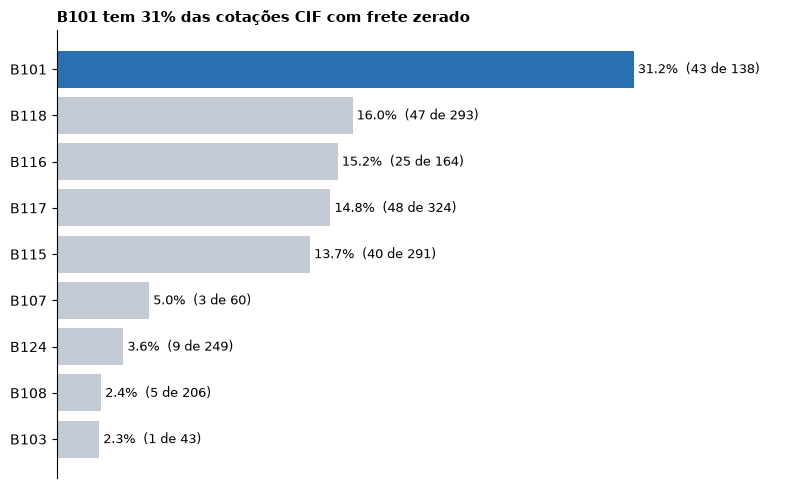

In [24]:
f4 = resultados["5.4 CIF frete zero"].query("Frete_zero > 0").sort_values("% frete zero", ascending=False)
barh(f4["Cód. Expedição"], f4["% frete zero"],
     f"{f4['Cód. Expedição'].iloc[0]} tem {f4['% frete zero'].iloc[0]:.0f}% das cotações CIF com frete zerado",
     destaque=1, fmt="{:.1f}%", extra=f4["Frete_zero"].astype(str) + " de " + f4["Total_CIF"].astype(str))

In [25]:
# evidências citadas na recomendação abaixo
z = cif[cif["Frete zero"]]
print(f"CIF com frete zero: {len(z)} de {len(cif)} ({len(z) / len(cif) * 100:.1f}%)")
print()
print("Por TipoCotação:", z["TipoCotação"].value_counts().to_dict())
print("Por status:", z["Status da Cotação"].value_counts().to_dict())

# 5 expedições com mais fretes zerados: qtd aprovadas com frete zero x frete típico das demais CIF
top5 = z["Cód. Expedição"].value_counts().head(5).index
ref = cif[(cif["Frete Comercial"] != 0) & cif["Frete Comercial"].notna()]
ev5 = pd.DataFrame({
    "Frete zero": z["Cód. Expedição"].value_counts().loc[top5],
    "Aprovadas c/ frete zero": z[z["Status da Cotação"] == "Aprovada"]["Cód. Expedição"].value_counts().reindex(top5),
    "Mediana |frete| das demais CIF": ref[ref["Cód. Expedição"].isin(top5)].groupby("Cód. Expedição")["Frete Comercial"].apply(lambda x: x.abs().median()).round(1),
})
print()
print(f"Top 5 expedições = {ev5['Frete zero'].sum()} dos {len(z)} fretes zerados ({ev5['Frete zero'].sum() / len(z) * 100:.0f}%)")
ev5

CIF com frete zero: 221 de 2768 (8.0%)

Por TipoCotação: {'Banda': 219, 'PrecoFixo': 2}
Por status: {'Aprovada': 178, 'Rejeitada': 37, 'Aguardando aprovação': 6}

Top 5 expedições = 203 dos 221 fretes zerados (92%)


,Frete zero,Aprovadas c/ frete zero,Mediana |frete| das demais CIF
Cód. Expedição,,,
B101,43,37,117.4
B115,40,30,199.6
B116,25,22,128.5
B117,48,42,73.7
B118,47,30,140.2


In [26]:
# cotações sem match: quais são (tipo e Incoterm)
sm = base[base["Match SalesForce"] == "Não"]
print("Sem match por TipoCotação:", sm["TipoCotação"].fillna("vazio").value_counts().to_dict())
print("Sem match por Incoterm:", sm["Incoterm"].value_counts().to_dict())

Sem match por TipoCotação: {'vazio': 88, 'Banda': 2}
Sem match por Incoterm: {'Sem informação do Sales Force': 89, 'CIF': 1}


In [27]:
# Incoterm "Sem informação do Sales Force" não é CIF (fora de 5.4), mas pode esconder frete CIF -> dimensiono
print(base["Incoterm"].value_counts())
print(base.loc[base["Incoterm"].str.startswith("Sem"), "Match SalesForce"].value_counts())

Incoterm
CIF                              2768
FOB                              1102
FOB Dirigido                      246
Sem informação do Sales Force     238
Name: count, dtype: int64
Match SalesForce
Sim    149
Não     89
Name: count, dtype: int64


**Recomendação – cotações CIF sem informação de frete**

Em CIF o frete comercial compõe o preço, então cotação sem frete é preço sem um de seus componentes.
- **Frete zerado:** 221 das 2.768 cotações CIF (8,0%), 219 delas Banda. 178 foram aprovadas. Cinco expedições (B117, B118, B101, B115, B116) concentram 203 dos 221, e B101 chega a 31% das suas CIF.
- **Impacto:** nessas expedições as demais CIF têm frete mediano (em módulo) de 74 a 200, enquanto as aprovadas com frete zero (22 a 42 por expedição) saíram sem esse componente. Se o zero for falta de preenchimento, o preço aprovado ficou menor que o necessário.
- **Sem informação:** 90 cotações não cruzaram com o SalesForce (88 sem TipoCotação, 2 Banda). Só 1 é CIF (B237); as outras 89 têm Incoterm "Sem informação do Sales Force", então não dá para saber se são CIF.

**Ação prática:** (1) pedir à logística/comercial a confirmação do frete das cinco expedições, separando isenção real de campo não preenchido;
(2) corrigir no SalesForce as 90 cotações sem correspondência (chave ID SAP + Material + Expedição) e informar o Incoterm das 89;
(3) enquanto isso, marcar CIF com frete zero ou ausente como "frete a confirmar" e exigir justificativa para aprovar;
(4) reprecificar as 178 aprovadas se o zero se confirmar como erro.

In [28]:
with pd.ExcelWriter("analises.xlsx") as w:
    for nome, df in resultados.items():
        df.to_excel(w, sheet_name=nome, index=False)